In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("Black_Friday_UTF8.csv")

# Display first 5 rows
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [22]:
# Data Baase Information
"""
Display information about the dataset, including the number of
rows, columns, data types, and non-null values.
"""

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  str    
 2   Gender                      550068 non-null  str    
 3   Age                         550068 non-null  str    
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  str    
 6   Stay_In_Current_City_Years  550068 non-null  str    
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 50.4 MB


In [23]:
# Summary Statistics
"""
Generate descriptive statistics such as count, mean, standard
deviation, minimum, maximum, and quartiles for numerical columns.
"""

df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [24]:
# Missing values 
"""
Check for missing values in each column to identify incomplete
data that may require preprocessing.
"""


df.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

In [25]:
# Duplicacte values
"""
Identify duplicate records to ensure data quality before analysis.
"""

df.duplicated().sum()

np.int64(0)

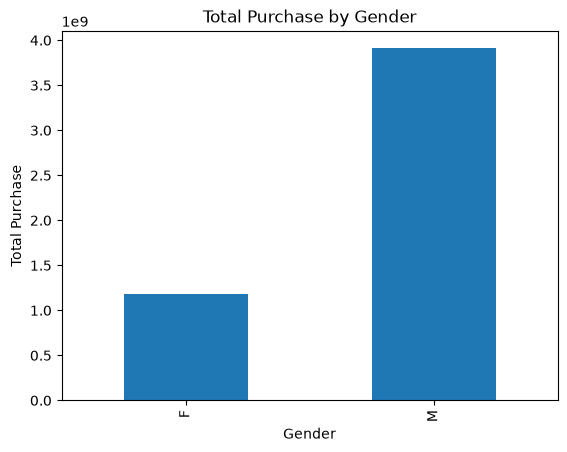

In [26]:
# Total Sales by Gender
"""
Analyze and visualize the total purchase amount for male and
female customers using a bar chart.
"""

df.groupby("Gender")["Purchase"].sum().plot(kind="bar")
plt.title("Total Purchase by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Purchase")
plt.show()

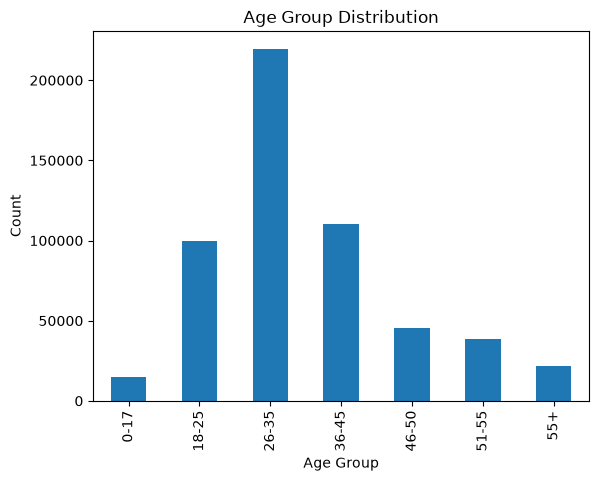

In [27]:
# Age Distribution
"""
Visualize the distribution of customers across different age
groups to identify the most active customer segment.
"""

df["Age"].value_counts().sort_index().plot(kind="bar")
plt.title("Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.show()

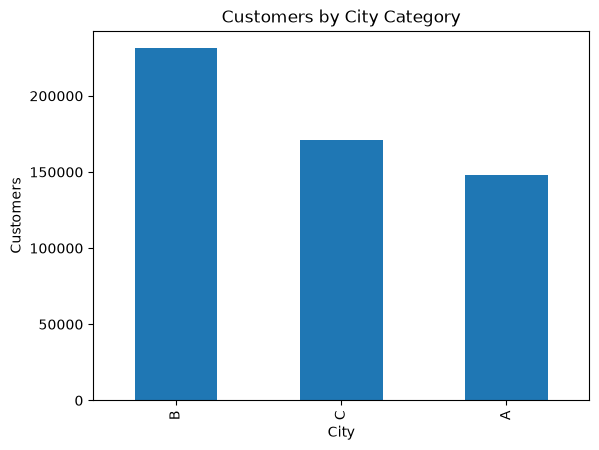

In [28]:
# City Category Distribution
"""
Display the distribution of customers across city categories
to understand customer concentration by location.
"""

df["City_Category"].value_counts().plot(kind="bar")
plt.title("Customers by City Category")
plt.xlabel("City")
plt.ylabel("Customers")
plt.show()

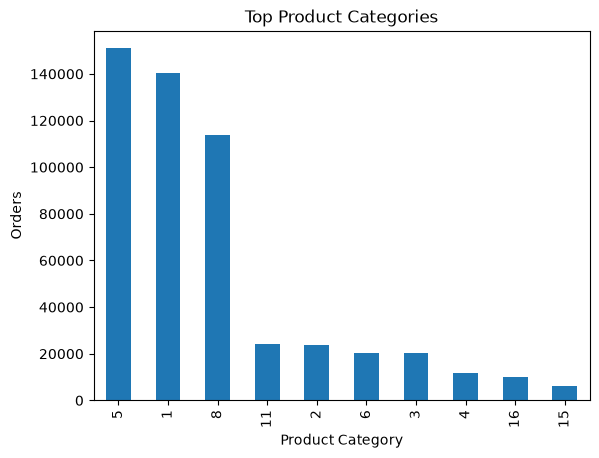

In [29]:
# Top Product Categories
"""
Identify the most frequently purchased product categories
using a bar chart.
"""

df["Product_Category_1"].value_counts().head(10).plot(kind="bar")
plt.title("Top Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Orders")
plt.show()

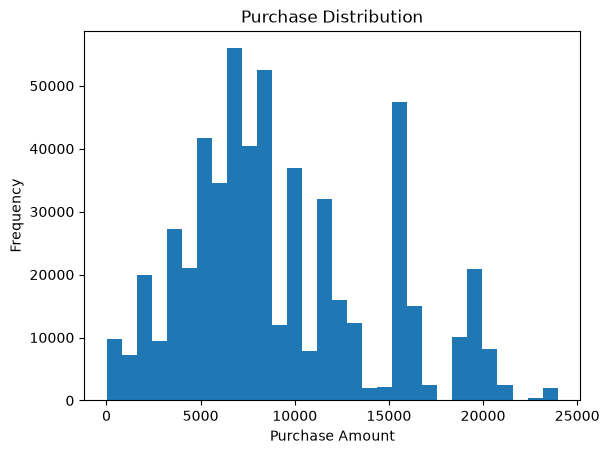

In [30]:
# Purchase Distribution
"""
Visualize the distribution of purchase amounts using a histogram
to understand customer spending patterns.
"""

plt.hist(df["Purchase"], bins=30)
plt.title("Purchase Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

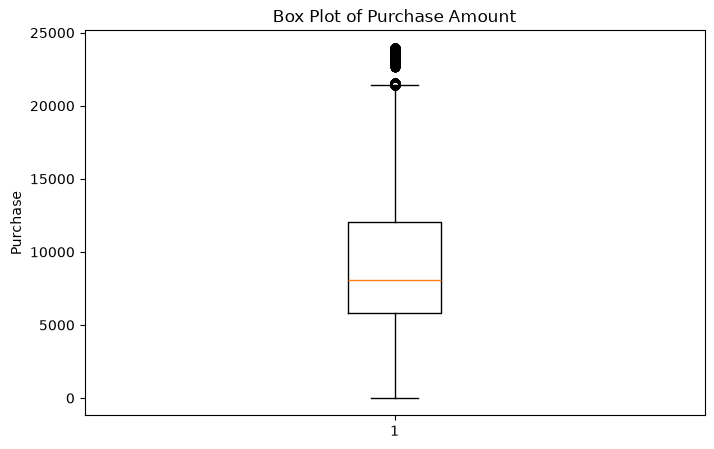

In [31]:
# Outlier Detection
"""
Detect outliers in the Purchase column using the IQR method
and visualize them with a box plot.
"""

plt.figure(figsize=(8,5))
plt.boxplot(df["Purchase"])
plt.title("Box Plot of Purchase Amount")
plt.ylabel("Purchase")
plt.show()

In [33]:
# Detect outliers using IQR

Q1 = df["Purchase"].quantile(0.25)
Q3 = df["Purchase"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Purchase"] < lower) | (df["Purchase"] > upper)]

print("Number of Outliers:", len(outliers))

Number of Outliers: 2677


In [34]:
# Correlation Analysis
"""
Calculate the correlation between numerical variables to
understand relationships within the dataset.
"""

numeric_df = df.select_dtypes(include=["number"])

correlation = numeric_df.corr()

correlation

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
User_ID,1.000000,-0.023971,0.020443,0.003825,0.001529,0.003419,0.004716
Occupation,-0.023971,1.000000,0.024280,-0.007618,-0.000384,0.013263,0.020833
Marital_Status,0.020443,0.024280,1.000000,0.019888,0.015138,0.019473,-0.000463
Product_Category_1,0.003825,-0.007618,0.019888,1.000000,0.540583,0.229678,-0.343703
Product_Category_2,0.001529,-0.000384,0.015138,0.540583,1.000000,0.543649,-0.209918
Product_Category_3,0.003419,0.013263,0.019473,0.229678,0.543649,1.000000,-0.022006
Purchase,0.004716,0.020833,-0.000463,-0.343703,-0.209918,-0.022006,1.000000


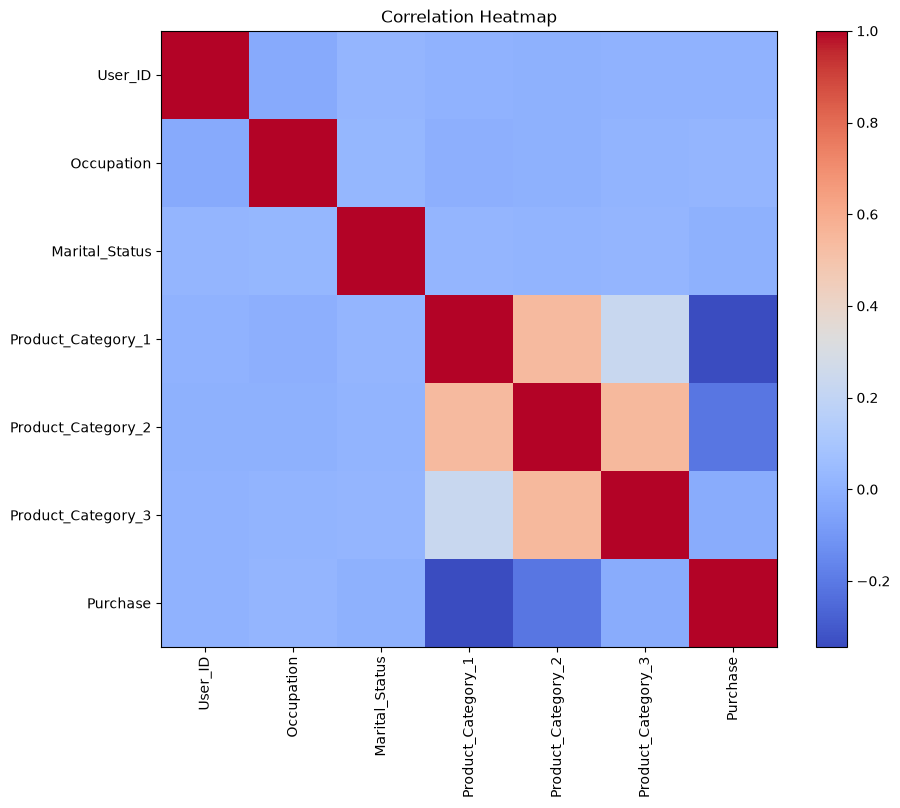

In [35]:
# Correlation Heatmap
"""
Visualize the correlation matrix using a heatmap to identify
positive and negative relationships between numerical features.
"""

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')

plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Heatmap")

plt.show()

In [36]:
# Highest Spending Age Group
"""
Determine which age group contributes the highest total sales.
"""

age_sales = df.groupby("Age")["Purchase"].sum().sort_values(ascending=False)
print(age_sales)

Age
26-35    2031770578
36-45    1026569884
18-25     913848675
46-50     420843403
51-55     367099644
55+       200767375
0-17      134913183
Name: Purchase, dtype: int64


In [37]:
#Highest Spending Occupation
"""
Identify the occupations that generate the highest purchase
amounts.
"""

occupation_sales = df.groupby("Occupation")["Purchase"].sum().sort_values(ascending=False)
print(occupation_sales)

Occupation
4     666244484
0     635406958
7     557371587
1     424614144
17    393281453
12    305449446
20    296570442
14    259454692
16    238346955
2     238028583
6     188416784
3     162002168
15    118960211
10    115844465
5     113649759
11    106751618
19     73700617
13     71919481
18     60721461
9      54340046
8      14737388
Name: Purchase, dtype: int64


In [38]:
# Highest Spending City Category
"""
Analyze total sales across different city categories to
identify the highest revenue-generating location.
"""

city_sales = df.groupby("City_Category")["Purchase"].sum()
print(city_sales)

City_Category
A    1316471661
B    2115533605
C    1663807476
Name: Purchase, dtype: int64


In [39]:
# Top 10 Customers
"""
Identify the top 10 customers based on their total purchase
amount.
"""

top_customers = df.groupby("User_ID")["Purchase"].sum().sort_values(ascending=False).head(10)
print(top_customers)

User_ID
1004277    10536909
1001680     8699596
1002909     7577756
1001941     6817493
1000424     6573609
1004448     6566245
1005831     6512433
1001015     6511314
1003391     6477160
1001181     6387961
Name: Purchase, dtype: int64


In [40]:
# Top Product Categories
"""
Analyze total sales by product category to determine the
best-performing product categories.
"""

category_sales = df.groupby("Product_Category_1")["Purchase"].sum().sort_values(ascending=False)
print(category_sales)

Product_Category_1
1     1910013754
5      941835229
8      854318799
6      324150302
2      268516186
3      204084713
16     145120612
11     113791115
10     100837301
15      92969042
7       60896731
4       27380488
14      20014696
18       9290201
9        6370324
17       5878699
12       5331844
13       4008601
20        944727
19         59378
Name: Purchase, dtype: int64


In [41]:
#Export Clean Dataset
"""
Export the cleaned dataset to a new CSV file for future
analysis and visualization.
"""

df.to_csv("Black_Friday_Cleaned.csv", index=False)

print("Dataset Exported Successfully")

Dataset Exported Successfully


# Key Insights

- Male customers generated higher overall sales than female customers.
- Customers aged 26–35 contributed the highest revenue.
- City Category B recorded the highest sales.
- Product Category 1 was the most popular category.
- Missing values were present only in Product_Category_2 and Product_Category_3.
- No duplicate records were found in the dataset.

# Conclusion

The Black Friday dataset was successfully analyzed using Python. Data exploration, data cleaning, visualization, outlier detection, and correlation analysis were performed to understand customer purchasing behavior. The cleaned dataset was exported for further analysis and Power BI dashboard development.